<a href="https://colab.research.google.com/github/2025cipooshangowdasb-sudo/dav_lab_programs/blob/main/final%20project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DAES Experiential Learning Assignment
## Netflix Movies and TV Shows – Data Analysis

**Platform:** Google Colab  
**Language:** Python  
**Libraries:** Pandas, NumPy, Matplotlib and Seaborn  
**Dataset:** [Netflix Movies and TV Shows – Kaggle](https://www.kaggle.com/datasets/shivamb/netflix-shows)

### Objectives
1. Load and understand the Netflix dataset.
2. Clean missing values and duplicate records.
3. Perform exploratory data analysis (EDA).
4. Create visualizations.
5. Summarize meaningful insights and conclusions.

**How to use:** Run the cells from top to bottom. When asked, upload the file named `netflix_titles.csv` downloaded from Kaggle.


## 1. Import the required libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


## 2. Upload and load the dataset

In [8]:
import os
import pandas as pd

# Look for netflix_titles.csv in the directory
file_name = 'netflix_titles.csv'

if os.path.exists(file_name):
    df = pd.read_csv(file_name)
    print("Dataset loaded successfully from local file")
else:
    try:
        from google.colab import files
        print("Please upload netflix_titles.csv:")
        uploaded = files.upload()
        file_name = next(iter(uploaded))
        df = pd.read_csv(file_name)
        print("Dataset loaded successfully")
    except Exception as e:
        print("Could not load the file automatically. Please ensure 'netflix_titles.csv' is uploaded to the environment.")

print("File in use:", file_name)

Dataset loaded successfully from local file
File in use: netflix_titles.csv


## 3. Display the first five rows

In [9]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 4. Check the dataset shape and column names

In [23]:
print("Number of rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Number of rows and columns: (8807, 14)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description', 'year_added', 'month_added']


## 5. Understand the dataset

In [11]:
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Statistical summary:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


## 6. Check missing values and duplicate rows

In [12]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Number of duplicate rows: 0


## 7. Clean the dataset

In [13]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing text values
text_columns = ["director", "cast", "country", "rating",
                "duration", "date_added"]

for column in text_columns:
    if column in df.columns:
        df[column] = df[column].fillna("Unknown")

# Convert date_added into a date format
df["date_added"] = pd.to_datetime(
    df["date_added"].str.strip(),
    errors="coerce"
)

print("Data cleaning completed")
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Data cleaning completed

Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


## 8. Data preprocessing

In [14]:
# Create year and month columns from the date Netflix added the title
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# Remove extra spaces from country names
df["country"] = df["country"].str.strip()

print("Preprocessing completed")
display(df.head())

Preprocessing completed


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,9.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,9.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,9.0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,9.0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,9.0


## 9. Compare Movies and TV Shows

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


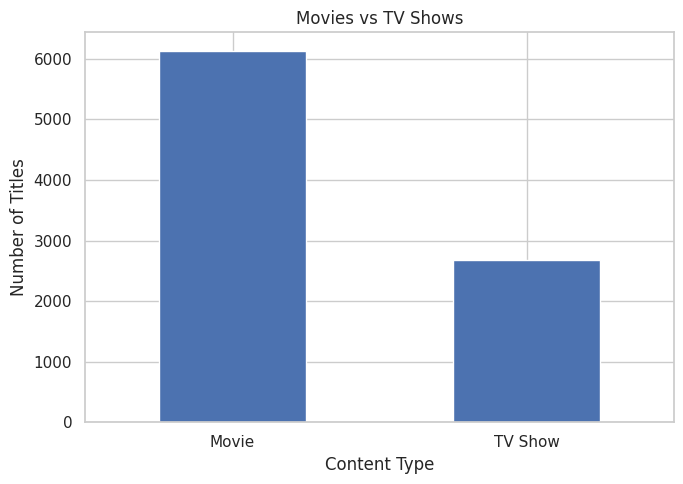

In [15]:
content_counts = df["type"].value_counts()
print(content_counts)

content_counts.plot(kind="bar", figsize=(7, 5), title="Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Find the top 10 countries

country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


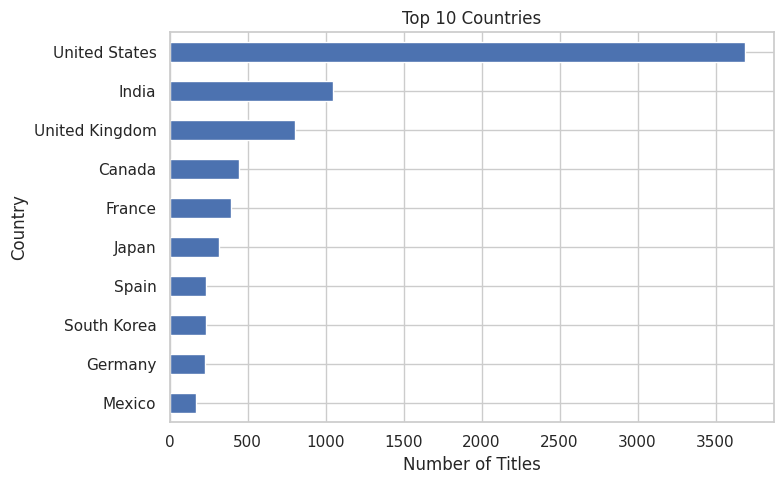

In [16]:
# A title can have more than one country, so split country names
countries = df.loc[df["country"] != "Unknown", "country"].dropna()
countries = countries.str.split(",").explode().str.strip()

top_countries = countries.value_counts().head(10)
print(top_countries)

top_countries.sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 10 Countries"
)
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 11. Find the top 10 genres

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


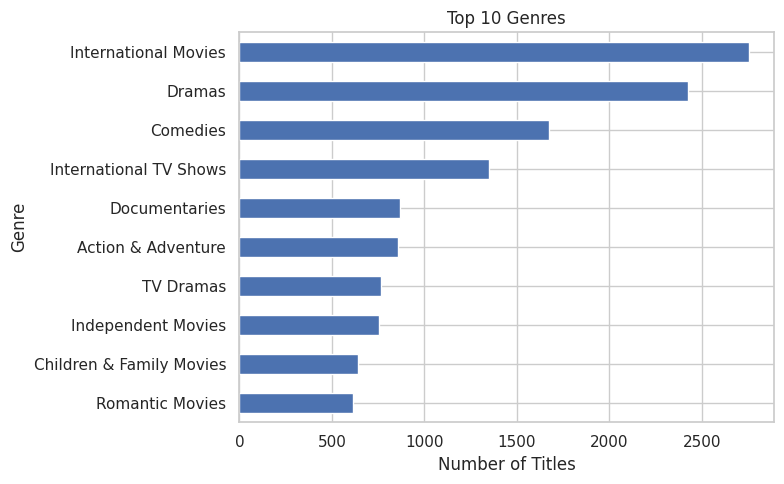

In [17]:
genres = df["listed_in"].dropna().str.split(",").explode().str.strip()
top_genres = genres.value_counts().head(10)

print(top_genres)

top_genres.sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 10 Genres"
)
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

## 12. Analyze content by release year

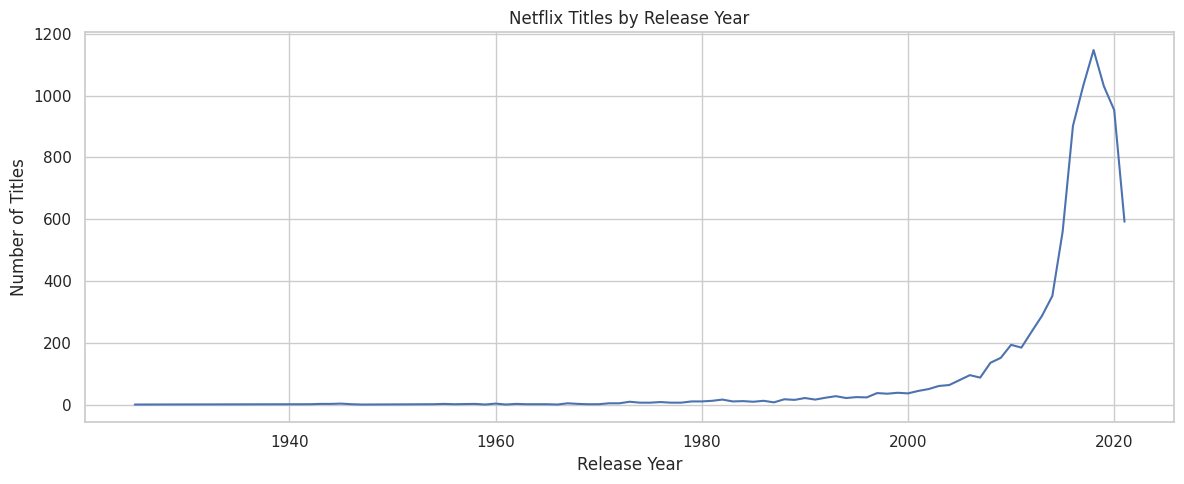

In [18]:
release_year_counts = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(release_year_counts.index, release_year_counts.values)
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.tight_layout()
plt.show()

## 13. Analyze content ratings

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


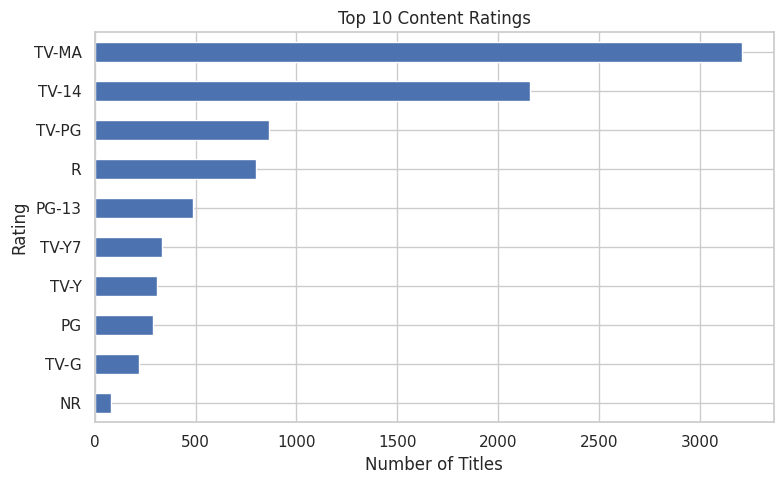

In [19]:
rating_counts = df["rating"].value_counts().head(10)
print(rating_counts)

rating_counts.sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 10 Content Ratings"
)
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

## 14. Analyze movie durations

Movie duration summary:


,duration_minutes
count,6128.000000
mean,99.577187
std,28.290593
min,3.000000
25%,87.000000
50%,98.000000
75%,114.000000
max,312.000000


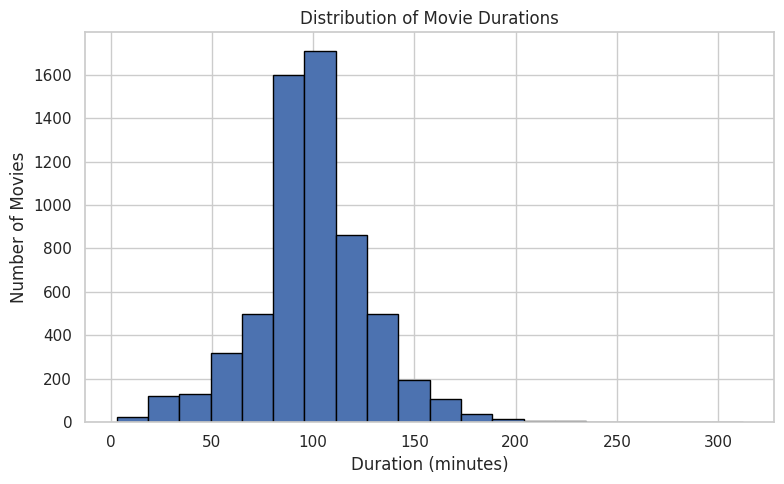

In [20]:
# Select movies and extract the number of minutes from duration
movies = df[df["type"] == "Movie"].copy()

movies["duration_minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

print("Movie duration summary:")
display(movies["duration_minutes"].describe())

plt.figure(figsize=(8, 5))
plt.hist(movies["duration_minutes"].dropna(), bins=20, edgecolor="black")
plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

## 15. Generate key insights

In [21]:
print("NETFLIX DATA ANALYSIS - KEY INSIGHTS")
print("------------------------------------")
print("Total titles:", len(df))
print("Total movies:", (df["type"] == "Movie").sum())
print("Total TV shows:", (df["type"] == "TV Show").sum())

if not df["type"].mode().empty:
    print("Most common content type:", df["type"].mode()[0])

if len(top_genres) > 0:
    print("Most common genre:", top_genres.index[0])

if len(top_countries) > 0:
    print("Top country in this dataset:", top_countries.index[0])

known_ratings = df.loc[df["rating"] != "Unknown", "rating"]
if not known_ratings.mode().empty:
    print("Most common rating:", known_ratings.mode()[0])

average_duration = movies["duration_minutes"].mean()
if pd.notna(average_duration):
    print("Average movie duration:", round(average_duration, 2), "minutes")

NETFLIX DATA ANALYSIS - KEY INSIGHTS
------------------------------------
Total titles: 8807
Total movies: 6131
Total TV shows: 2676
Most common content type: Movie
Most common genre: International Movies
Top country in this dataset: United States
Most common rating: TV-MA
Average movie duration: 99.58 minutes


## 16. Save the cleaned dataset

In [22]:
output_file = "Netflix_Cleaned_Data.csv"
df.to_csv(output_file, index=False)
print("Cleaned dataset saved as:", output_file)

# Download the cleaned CSV file in Google Colab
files.download(output_file)

Cleaned dataset saved as: Netflix_Cleaned_Data.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>